# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Malfino Muhammad Willianz | 5054251028 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import os

# Harus diset sebelum CUDA dipakai agar operasi cuBLAS deterministik
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import gzip
import time
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Seed agar eksperimen reproducible
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Reproducibility pada GPU: paksa algoritma deterministik (tanpa ini, hasil bisa
# berbeda antar-run karena cuDNN/cuBLAS memakai kernel dan atomics yang tidak deterministik)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {device}")
if device == "cuda":
    print(f"GPU     : {torch.cuda.get_device_name(0)}")

PyTorch : 2.13.0+cu129
Device  : cuda
GPU     : NVIDIA GeForce RTX 5060 Ti


In [2]:
# Dataset asli tersedia di Kaggle dalam format CSV (1 kolom label + 784 kolom piksel).
# Jika CSV belum ada, unduh file IDX resmi dari repo Fashion-MNIST lalu konversi ke format CSV yang sama,
# sehingga notebook ini tetap bisa dijalankan dari nol (misalnya di Colab/Kaggle).
DATA_DIR = "data"
TRAIN_CSV = f"{DATA_DIR}/fashion-mnist_train.csv"
TEST_CSV = f"{DATA_DIR}/fashion-mnist_test.csv"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion"


def idx_images(path):
    # Format IDX: 4 byte magic, 4 byte jumlah gambar, 4 byte baris, 4 byte kolom
    with gzip.open(path, "rb") as f:
        f.read(4)
        n = int.from_bytes(f.read(4), "big")
        rows = int.from_bytes(f.read(4), "big")
        cols = int.from_bytes(f.read(4), "big")
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows * cols)


def idx_labels(path):
    with gzip.open(path, "rb") as f:
        f.read(4)
        f.read(4)
        return np.frombuffer(f.read(), dtype=np.uint8)


def build_csv(images_name, labels_name, out_path):
    for name in (images_name, labels_name):
        if not os.path.exists(f"{DATA_DIR}/{name}"):
            urllib.request.urlretrieve(f"{BASE_URL}/{name}", f"{DATA_DIR}/{name}")
    df = pd.DataFrame(idx_images(f"{DATA_DIR}/{images_name}"))
    df.insert(0, "label", idx_labels(f"{DATA_DIR}/{labels_name}"))
    df.to_csv(out_path, index=False)


os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(TRAIN_CSV):
    build_csv("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", TRAIN_CSV)
if not os.path.exists(TEST_CSV):
    build_csv("t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz", TEST_CSV)

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Ukuran data train:", train_df.shape, "(baris, kolom)")
print("Ukuran data test :", test_df.shape, "(baris, kolom)")
print("Kolom pertama    :", train_df.columns[0], "| jumlah kolom piksel:", train_df.shape[1] - 1)
print("Rentang nilai piksel:", int(train_df.iloc[:, 1:].values.min()), "-", int(train_df.iloc[:, 1:].values.max()))

Ukuran data train: (60000, 785) (baris, kolom)
Ukuran data test : (10000, 785) (baris, kolom)
Kolom pertama    : label | jumlah kolom piksel: 784
Rentang nilai piksel: 0 - 255


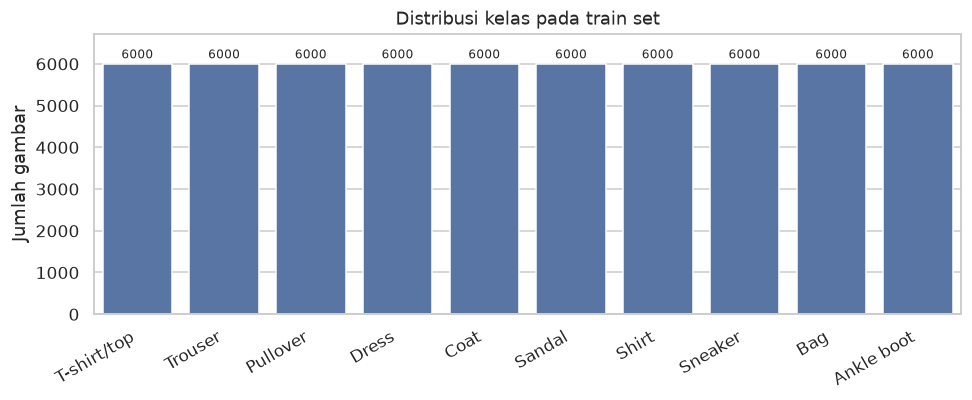

label
T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000

Jumlah gambar per kelas: 6000 - 6000 (dataset seimbang)


In [3]:
class_names = {
    0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle boot",
}

counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(9, 3.8))
sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values, color="#4C72B0")
for i, v in enumerate(counts.values):
    plt.text(i, v + 60, str(v), ha="center", va="bottom", fontsize=8)
plt.title("Distribusi kelas pada train set")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

print(counts.rename(index=class_names).to_string())
print(f"\nJumlah gambar per kelas: {counts.min()} - {counts.max()} (dataset seimbang)")

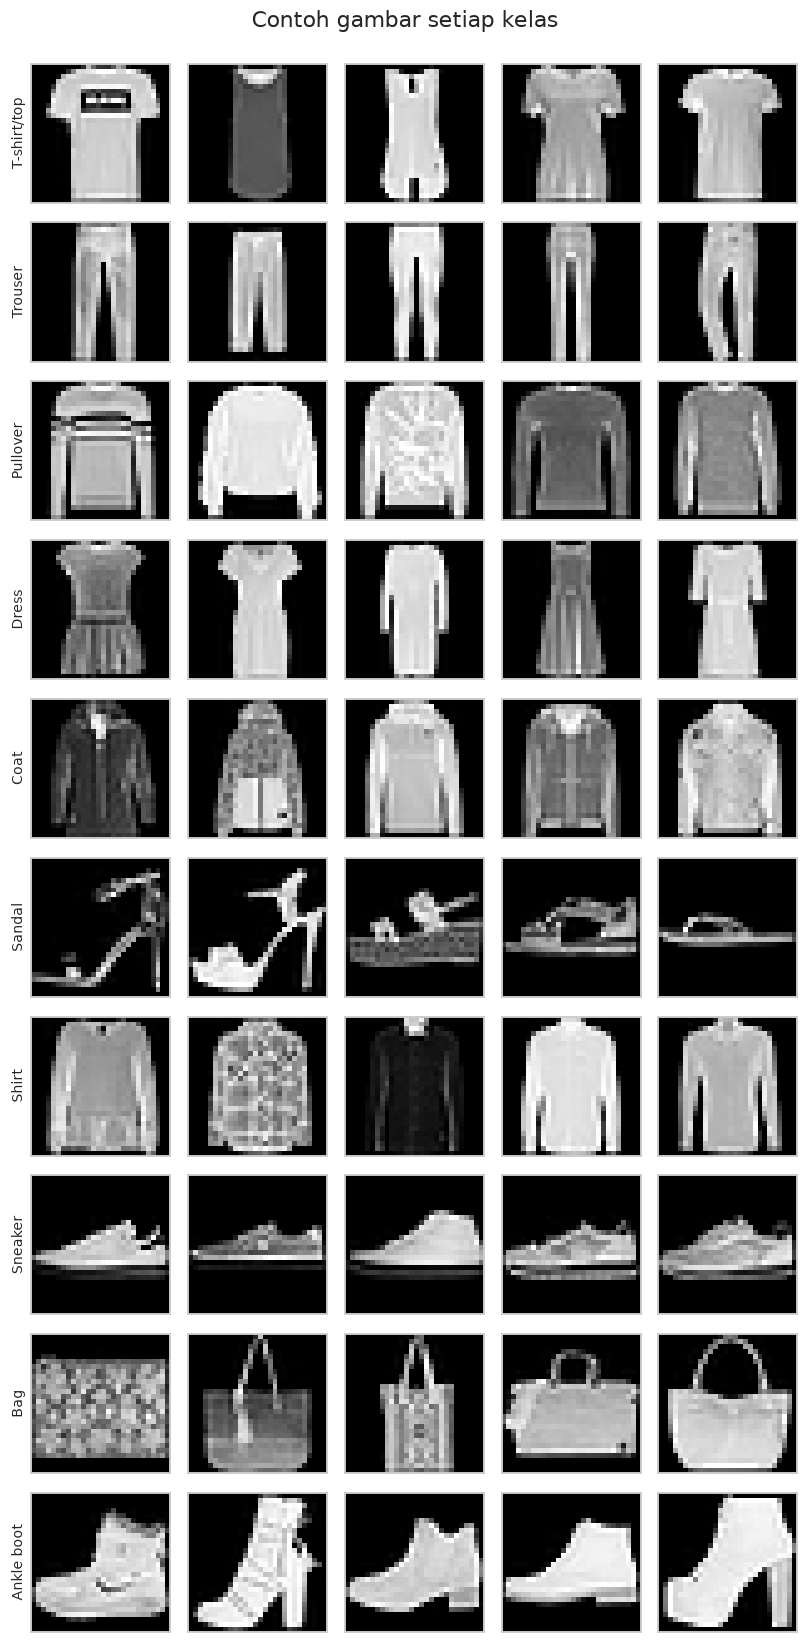

In [4]:
# Contoh gambar tiap kelas (10 kelas x 5 gambar)
fig, axes = plt.subplots(10, 5, figsize=(7.5, 15))
for row, cls in enumerate(range(10)):
    idxs = train_df.index[train_df["label"] == cls][:5]
    for col, idx in enumerate(idxs):
        ax = axes[row, col]
        ax.imshow(train_df.iloc[idx, 1:].values.reshape(28, 28), cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(class_names[cls], fontsize=9)
plt.suptitle("Contoh gambar setiap kelas", y=0.995)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

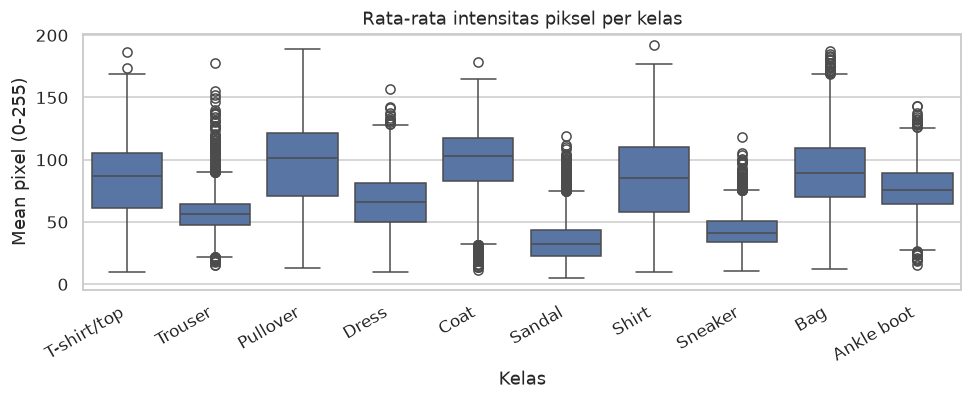

              mean    std
label                    
T-shirt/top  83.03  28.91
Trouser      56.84  14.52
Pullover     96.06  32.65
Dress        66.02  21.40
Coat         98.26  26.43
Sandal       34.87  15.84
Shirt        84.61  33.08
Sneaker      42.76  12.84
Bag          90.16  28.77
Ankle boot   76.81  18.30


In [5]:
# EDA tambahan 1: rata-rata piksel per gambar untuk setiap kelas (boxplot)
pixel_mean = train_df.iloc[:, 1:].mean(axis=1)
eda = pd.DataFrame({"label": train_df["label"], "mean_pixel": pixel_mean})

plt.figure(figsize=(9, 3.8))
sns.boxplot(data=eda, x="label", y="mean_pixel", color="#4C72B0")
plt.xticks(range(10), [class_names[i] for i in range(10)], rotation=30, ha="right")
plt.title("Rata-rata intensitas piksel per kelas")
plt.xlabel("Kelas"); plt.ylabel("Mean pixel (0-255)")
plt.tight_layout()
plt.show()

print(eda.groupby("label")["mean_pixel"].agg(["mean", "std"]).round(2)
        .rename(index=class_names).to_string())

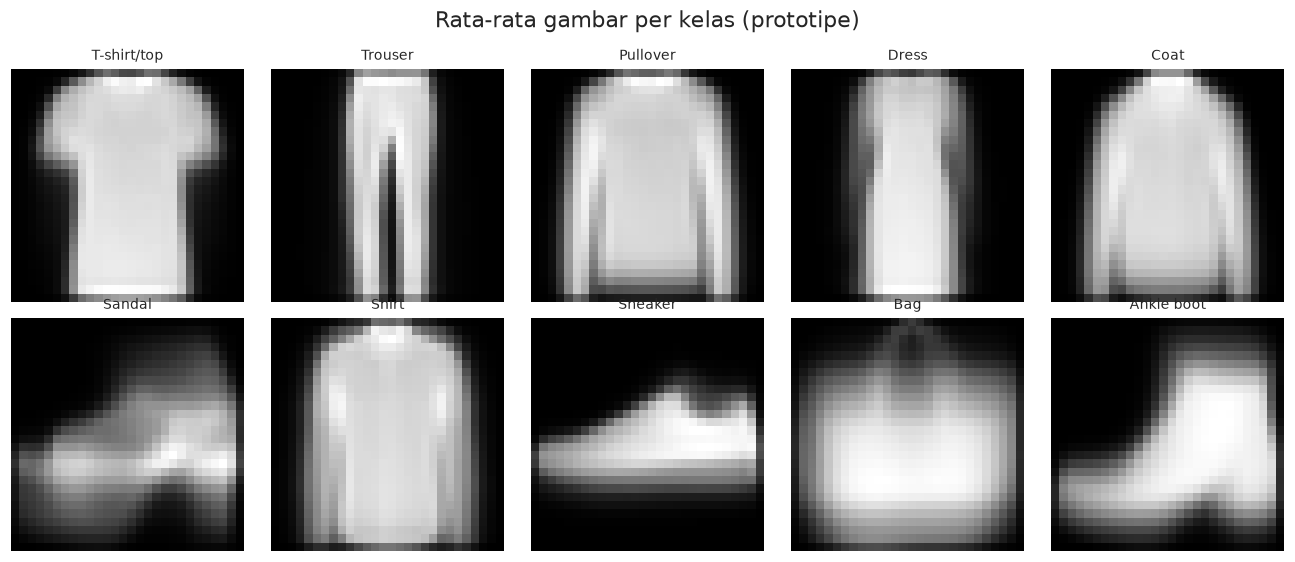

In [6]:
# EDA tambahan 2: gambar rata-rata (prototipe) tiap kelas
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, cls in zip(axes.ravel(), range(10)):
    mean_img = train_df.loc[train_df["label"] == cls, train_df.columns[1:]].values.mean(axis=0)
    ax.imshow(mean_img.reshape(28, 28), cmap="gray")
    ax.set_title(class_names[cls], fontsize=9)
    ax.axis("off")
plt.suptitle("Rata-rata gambar per kelas (prototipe)")
plt.tight_layout()
plt.show()

Dataset terdiri dari 60.000 gambar train dan 10.000 gambar test, masing-masing dengan satu kolom label dan 784 kolom piksel bernilai 0 sampai 255. Kelasnya seimbang: 6.000 gambar per kelas di train dan 1.000 per kelas di test. Karena itu accuracy sudah cukup adil sebagai metrik, tapi precision, recall, dan F1 macro tetap dilaporkan supaya kelas yang lemah kelihatan.

Kelas yang paling mirip adalah kelompok pakaian atas: T-shirt/top, Shirt, Pullover, Coat, dan Dress. Pada gambar prototipe, `Shirt` hampir tidak bisa dibedakan dari `T-shirt/top`, begitu juga `Pullover` dari `Coat`. Trouser, Bag, Sneaker, Ankle boot, dan Sandal punya siluet yang jelas.

Rata-rata intensitas piksel tertinggi ada pada `Coat` (98,26), `Pullover` (96,06), `Bag` (90,16), `Shirt` (84,61), dan `T-shirt/top` (83,03). Yang terendah `Sandal` (34,87) dan `Sneaker` (42,76), karena latar gelapnya dominan. Artinya yang membedakan kelas adalah pola bentuk lokal, bukan kecerahan keseluruhan. Ini alasan CNN dengan filter lokal seharusnya mengungguli ANN yang meratakan gambar.

Semua gambar sudah terpusat dan berskala seragam, jadi tidak perlu augmentasi crop atau rotasi, dan normalisasi 0-1 sudah cukup.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [7]:
# Pisahkan label (y) dan piksel (X)
y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns=["label"]).values

y_test = test_df["label"].values
X_test = test_df.drop(columns=["label"]).values

print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test      :", X_test.shape, "| y_test      :", y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test      : (10000, 784) | y_test      : (10000,)


In [8]:
# Normalisasi nilai piksel ke rentang 0-1
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Nilai minimum:", float(X_train_full.min()), "| nilai maksimum:", float(X_train_full.max()))
print("Tipe data    :", X_train_full.dtype)

Nilai minimum: 0.0 | nilai maksimum: 1.0
Tipe data    : float32


In [9]:
# Bagi train set menjadi train : validation = 90 : 10 dengan stratify
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED)

print(f"Train      : {X_train.shape[0]:5d} gambar")
print(f"Validation : {X_val.shape[0]:5d} gambar")
print(f"Test       : {X_test.shape[0]:5d} gambar")
print()
print("Jumlah gambar per kelas di train set:")
print(pd.Series(y_train).value_counts().sort_index().rename(index=class_names).to_string())

Train      : 54000 gambar
Validation :  6000 gambar
Test       : 10000 gambar

Jumlah gambar per kelas di train set:
T-shirt/top    5400
Trouser        5400
Pullover       5400
Dress          5400
Coat           5400
Sandal         5400
Shirt          5400
Sneaker        5400
Bag            5400
Ankle boot     5400


In [10]:
# Konversi ke tensor: X float32 (N, 1, 28, 28), y long (wajib untuk nn.CrossEntropyLoss)
def to_image_tensor(X):
    return torch.tensor(X, dtype=torch.float32).view(-1, 1, 28, 28)


X_train_t = to_image_tensor(X_train)
X_val_t = to_image_tensor(X_val)
X_test_t = to_image_tensor(X_test)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print("Bentuk X_train:", tuple(X_train_t.shape), "| tipe:", X_train_t.dtype)
print("Bentuk y_train:", tuple(y_train_t.shape), "| tipe:", y_train_t.dtype)
print("Jumlah batch train per epoch:", len(train_loader))

Bentuk X_train: (54000, 1, 28, 28) | tipe: torch.float32
Bentuk y_train: (54000,) | tipe: torch.int64
Jumlah batch train per epoch: 422


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [11]:
class ANN(nn.Module):
    # Baseline: flatten gambar 28x28 menjadi 784, lalu 2 hidden layer

    def __init__(self, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes),   # output logit, tanpa Softmax
        )

    def forward(self, x):
        return self.net(x)


model_ann = ANN().to(device)
print(model_ann)
print("Jumlah parameter:", f"{sum(p.numel() for p in model_ann.parameters()):,}")

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235,146


In [12]:
def train_model(model, train_loader, val_loader, criterion, optimizer,
                epochs, device=device, verbose=True):
    # Training loop generik untuk klasifikasi multikelas (output logit)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "time": []}

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        # ---- training ----
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            total += yb.size(0)
        history["train_loss"].append(running_loss / total)
        history["train_acc"].append(correct / total)

        # ---- validation ----
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                loss = criterion(out, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (out.argmax(dim=1) == yb).sum().item()
                total += yb.size(0)
        history["val_loss"].append(running_loss / total)
        history["val_acc"].append(correct / total)
        history["time"].append(time.time() - t0)

        if verbose:
            print(f"Epoch {epoch:2d}/{epochs} | "
                  f"train_loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.4f} | "
                  f"val_loss {history['val_loss'][-1]:.4f} acc {history['val_acc'][-1]:.4f} | "
                  f"{history['time'][-1]:.1f}s")
    return history


def plot_learning_curve(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train", marker="o", ms=3)
    axes[0].plot(epochs, history["val_loss"], label="Validation", marker="o", ms=3)
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-Entropy Loss"); axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="Train", marker="o", ms=3)
    axes[1].plot(epochs, history["val_acc"], label="Validation", marker="o", ms=3)
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()


def predict_labels(model, loader):
    # Kembalikan prediksi kelas (argmax) sebagai numpy array
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


# Hyperparameter (dipakai sama untuk ketiga model agar perbandingan adil)
EPOCHS = 10
LR = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer_ann = torch.optim.Adam(model_ann.parameters(), lr=LR)

history_ann = train_model(model_ann, train_loader, val_loader, criterion, optimizer_ann, EPOCHS)

Epoch  1/10 | train_loss 0.5877 acc 0.7941 | val_loss 0.4112 acc 0.8577 | 0.7s


Epoch  2/10 | train_loss 0.4019 acc 0.8549 | val_loss 0.3631 acc 0.8682 | 0.4s


Epoch  3/10 | train_loss 0.3554 acc 0.8699 | val_loss 0.3562 acc 0.8697 | 0.4s


Epoch  4/10 | train_loss 0.3252 acc 0.8806 | val_loss 0.3293 acc 0.8760 | 0.4s


Epoch  5/10 | train_loss 0.3053 acc 0.8873 | val_loss 0.3097 acc 0.8853 | 0.4s


Epoch  6/10 | train_loss 0.2927 acc 0.8921 | val_loss 0.3049 acc 0.8858 | 0.4s


Epoch  7/10 | train_loss 0.2773 acc 0.8981 | val_loss 0.2935 acc 0.8918 | 0.4s


Epoch  8/10 | train_loss 0.2649 acc 0.9014 | val_loss 0.2949 acc 0.8930 | 0.4s


Epoch  9/10 | train_loss 0.2550 acc 0.9043 | val_loss 0.2779 acc 0.9003 | 0.4s


Epoch 10/10 | train_loss 0.2435 acc 0.9098 | val_loss 0.2889 acc 0.8983 | 0.4s


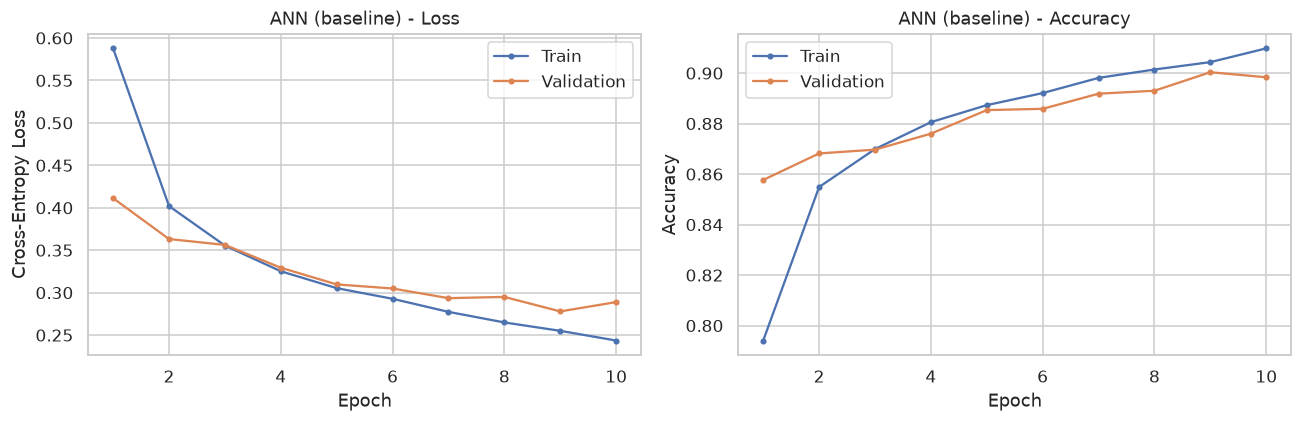

In [13]:
plot_learning_curve(history_ann, "ANN (baseline)")

In [14]:
y_pred_ann = predict_labels(model_ann, test_loader)

print("Bentuk prediksi:", y_pred_ann.shape)
print("Contoh prediksi (10 pertama):", y_pred_ann[:10])
print("Contoh label asli (10 pertama):", y_test[:10])
print(f"Akurasi pada test set: {accuracy_score(y_test, y_pred_ann):.4f}")

Bentuk prediksi: (10000,)
Contoh prediksi (10 pertama): [9 2 1 1 6 1 4 6 5 7]
Contoh label asli (10 pertama): [9 2 1 1 6 1 4 6 5 7]
Akurasi pada test set: 0.8832


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [15]:
# Perhitungan manual ukuran output dengan rumus (W - K + 2P) / S + 1:
# Input                         : 28 x 28
# Conv2d(1->32, k=3, p=1, s=1)  : (28 - 3 + 2*1)/1 + 1 = 28  -> 32 x 28 x 28
# MaxPool2d(2, s=2)             : (28 - 2)/2 + 1        = 14  -> 32 x 14 x 14
# Conv2d(32->64, k=3, p=1, s=1) : (14 - 3 + 2*1)/1 + 1  = 14  -> 64 x 14 x 14
# MaxPool2d(2, s=2)             : (14 - 2)/2 + 1        = 7   -> 64 x 7 x 7
# Flatten                       : 64 * 7 * 7 = 3136 fitur     -> Linear(3136, 128)
class SimpleCNN(nn.Module):
    # CNN sederhana: 2 blok Conv -> ReLU -> MaxPool, lalu classifier

    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes),   # output logit
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_cnn = SimpleCNN().to(device)
print(model_cnn)
print("Jumlah parameter:", f"{sum(p.numel() for p in model_cnn.parameters()):,}")

# Verifikasi ukuran output: cocokkan hasil hitung manual dengan bentuk tensor sebenarnya
dummy = torch.zeros(1, 1, 28, 28).to(device)
with torch.no_grad():
    feat = model_cnn.features(dummy)
print("\nBentuk output blok konvolusi:", tuple(feat.shape), "-> flatten:", feat.numel(), "fitur")
print("Bentuk output model:", tuple(model_cnn(dummy).shape))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421,642



Bentuk output blok konvolusi: (1, 64, 7, 7) -> flatten: 3136 fitur
Bentuk output model: (1, 10)


In [16]:
optimizer_cnn = torch.optim.Adam(model_cnn.parameters(), lr=LR)
history_cnn = train_model(model_cnn, train_loader, val_loader, criterion, optimizer_cnn, EPOCHS)

Epoch  1/10 | train_loss 0.5313 acc 0.8092 | val_loss 0.4424 acc 0.8297 | 0.7s


Epoch  2/10 | train_loss 0.3329 acc 0.8807 | val_loss 0.2992 acc 0.8908 | 0.7s


Epoch  3/10 | train_loss 0.2838 acc 0.8976 | val_loss 0.2487 acc 0.9127 | 0.7s


Epoch  4/10 | train_loss 0.2521 acc 0.9074 | val_loss 0.2491 acc 0.9063 | 0.7s


Epoch  5/10 | train_loss 0.2293 acc 0.9152 | val_loss 0.2185 acc 0.9200 | 0.7s


Epoch  6/10 | train_loss 0.2108 acc 0.9224 | val_loss 0.2182 acc 0.9170 | 0.7s


Epoch  7/10 | train_loss 0.1925 acc 0.9291 | val_loss 0.2032 acc 0.9212 | 0.7s


Epoch  8/10 | train_loss 0.1730 acc 0.9366 | val_loss 0.2056 acc 0.9230 | 0.7s


Epoch  9/10 | train_loss 0.1581 acc 0.9421 | val_loss 0.1947 acc 0.9303 | 0.7s


Epoch 10/10 | train_loss 0.1452 acc 0.9463 | val_loss 0.2068 acc 0.9262 | 0.7s


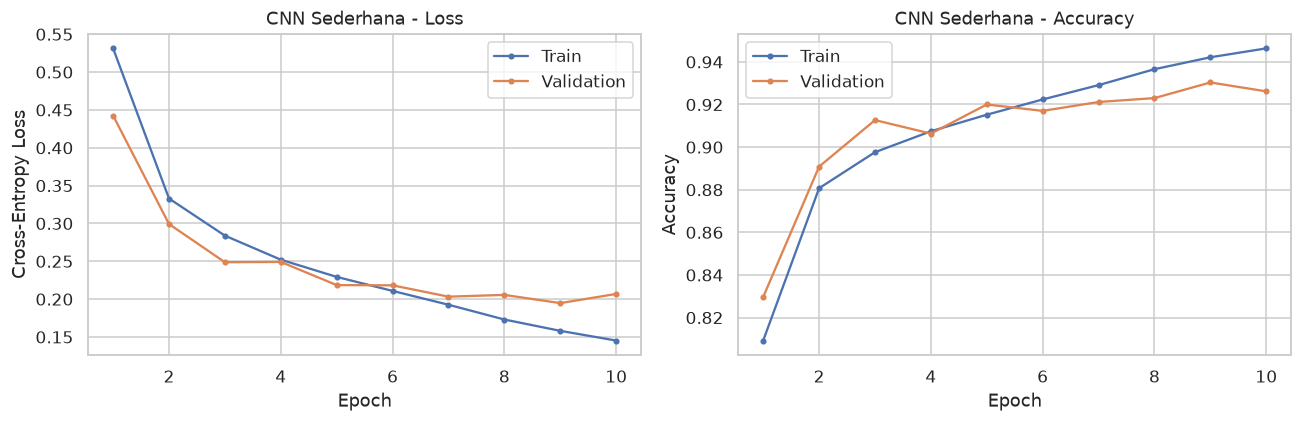

In [17]:
plot_learning_curve(history_cnn, "CNN Sederhana")

In [18]:
y_pred_cnn = predict_labels(model_cnn, test_loader)

print("Bentuk prediksi:", y_pred_cnn.shape)
print(f"Akurasi pada test set: {accuracy_score(y_test, y_pred_cnn):.4f}")

Bentuk prediksi: (10000,)
Akurasi pada test set: 0.9174


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [19]:
class CNNBatchNorm(nn.Module):
    # CNN 3.2 + BatchNorm2d setelah setiap Conv, BatchNorm1d + Dropout sebelum layer output

    def __init__(self, n_classes=10, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(128, n_classes),   # output logit
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_cnn_bn = CNNBatchNorm(p_dropout=0.5).to(device)
print(model_cnn_bn)
print("Jumlah parameter:", f"{sum(p.numel() for p in model_cnn_bn.parameters()):,}")

CNNBatchNorm(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 422,090


In [20]:
optimizer_cnn_bn = torch.optim.Adam(model_cnn_bn.parameters(), lr=LR)
history_cnn_bn = train_model(model_cnn_bn, train_loader, val_loader, criterion, optimizer_cnn_bn, EPOCHS)

Epoch  1/10 | train_loss 0.4320 acc 0.8593 | val_loss 0.2606 acc 0.9023 | 1.0s


Epoch  2/10 | train_loss 0.2789 acc 0.9026 | val_loss 0.2210 acc 0.9178 | 0.9s


Epoch  3/10 | train_loss 0.2380 acc 0.9142 | val_loss 0.2070 acc 0.9253 | 0.9s


Epoch  4/10 | train_loss 0.2110 acc 0.9240 | val_loss 0.1947 acc 0.9260 | 0.9s


Epoch  5/10 | train_loss 0.1940 acc 0.9288 | val_loss 0.2189 acc 0.9180 | 0.9s


Epoch  6/10 | train_loss 0.1719 acc 0.9368 | val_loss 0.2024 acc 0.9245 | 0.9s


Epoch  7/10 | train_loss 0.1587 acc 0.9420 | val_loss 0.1947 acc 0.9315 | 0.9s


Epoch  8/10 | train_loss 0.1494 acc 0.9441 | val_loss 0.2067 acc 0.9240 | 0.9s


Epoch  9/10 | train_loss 0.1342 acc 0.9500 | val_loss 0.1824 acc 0.9352 | 0.9s


Epoch 10/10 | train_loss 0.1266 acc 0.9531 | val_loss 0.1967 acc 0.9290 | 0.9s


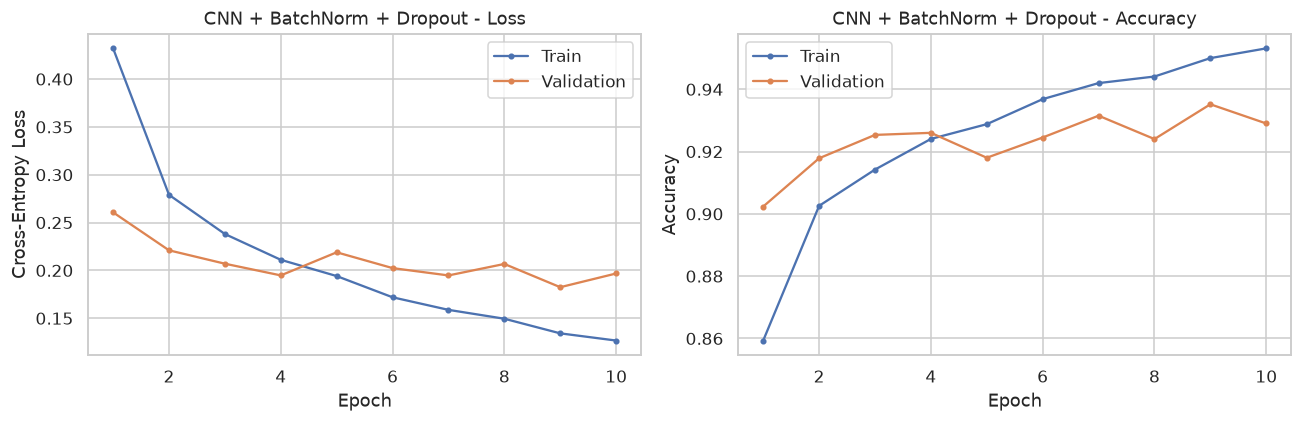

Perbandingan gap train vs validation (epoch terakhir):
Model                       train_acc   val_acc   gap_acc  train_loss  val_loss
ANN                            0.9098    0.8983   +0.0114      0.2435    0.2889
CNN Sederhana                  0.9463    0.9262   +0.0202      0.1452    0.2068
CNN + BN + Dropout             0.9531    0.9290   +0.0241      0.1266    0.1967

Rata-rata waktu per epoch:
  ANN                   : 0.45 s
  CNN Sederhana         : 0.70 s
  CNN + BN + Dropout    : 0.89 s


In [21]:
plot_learning_curve(history_cnn_bn, "CNN + BatchNorm + Dropout")

print("Perbandingan gap train vs validation (epoch terakhir):")
print(f"{'Model':26s} {'train_acc':>10s} {'val_acc':>9s} {'gap_acc':>9s} {'train_loss':>11s} {'val_loss':>9s}")
for name, h in [("ANN", history_ann), ("CNN Sederhana", history_cnn),
                ("CNN + BN + Dropout", history_cnn_bn)]:
    gap = h["train_acc"][-1] - h["val_acc"][-1]
    print(f"{name:26s} {h['train_acc'][-1]:10.4f} {h['val_acc'][-1]:9.4f} {gap:+9.4f} "
          f"{h['train_loss'][-1]:11.4f} {h['val_loss'][-1]:9.4f}")

print("\nRata-rata waktu per epoch:")
for name, h in [("ANN", history_ann), ("CNN Sederhana", history_cnn),
                ("CNN + BN + Dropout", history_cnn_bn)]:
    print(f"  {name:22s}: {np.mean(h['time']):.2f} s")

**Dibanding 3.2:** BatchNorm membuat kurva naik jauh lebih cepat. Akurasi validasi sudah 0,9080 di epoch 1 (CNN sederhana 0,8273) dengan loss validasi 0,2508 (CNN sederhana 0,4461), lalu mendatar di sekitar 0,93. Gap train-validation akhir sedikit lebih besar (+2,41 vs +2,02 poin) karena akurasi training lebih tinggi (0,9531 vs 0,9463). Loss validasi juga naik lagi dari 0,1812 di epoch 9 ke 0,1967 di epoch 10. Dropout 0,5 membantu menahan overfitting, tapi belum cukup untuk 10 epoch, dan early stopping di epoch 9 akan memberi hasil terbaik.

In [22]:
y_pred_cnn_bn = predict_labels(model_cnn_bn, test_loader)

print("Bentuk prediksi:", y_pred_cnn_bn.shape)
print(f"Akurasi pada test set: {accuracy_score(y_test, y_pred_cnn_bn):.4f}")

Bentuk prediksi: (10000,)
Akurasi pada test set: 0.9185


# 4. Evaluasi Model

In [23]:
models = {
    "ANN": (model_ann, y_pred_ann),
    "CNN Sederhana": (model_cnn, y_pred_cnn),
    "CNN + BatchNorm + Dropout": (model_cnn_bn, y_pred_cnn_bn),
}

rows = []
for name, (model, pred) in models.items():
    rows.append({
        "Model": name,
        "Jumlah Parameter": sum(p.numel() for p in model.parameters()),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1-Score (macro)": f1_score(y_test, pred, average="macro"),
    })

metrics_df = pd.DataFrame(rows).set_index("Model")
print(metrics_df.round(4).to_string())
print()
print("Metrik dihitung pada test set (10.000 gambar) yang tidak dipakai saat training/validasi.")

                           Jumlah Parameter  Accuracy  Precision (macro)  Recall (macro)  F1-Score (macro)
Model                                                                                                     
ANN                                  235146    0.8832             0.8847          0.8832            0.8819
CNN Sederhana                        421642    0.9174             0.9180          0.9174            0.9168
CNN + BatchNorm + Dropout            422090    0.9185             0.9204          0.9185            0.9188

Metrik dihitung pada test set (10.000 gambar) yang tidak dipakai saat training/validasi.


In [24]:
# Model terbaik dipilih berdasarkan F1-Score macro pada test set
best_name = metrics_df["F1-Score (macro)"].idxmax()
best_model = models[best_name][0]
y_pred_best = models[best_name][1]
print(f"Model terbaik berdasarkan F1-Score macro: {best_name}")
print(f"F1-Score macro = {metrics_df.loc[best_name, 'F1-Score (macro)']:.4f} | "
      f"Accuracy = {metrics_df.loc[best_name, 'Accuracy']:.4f}")

Model terbaik berdasarkan F1-Score macro: CNN + BatchNorm + Dropout
F1-Score macro = 0.9188 | Accuracy = 0.9185


In [25]:
print(f"Classification report - {best_name} (test set)\n")
print(classification_report(y_test, y_pred_best,
                            target_names=[class_names[i] for i in range(10)], digits=4))

Classification report - CNN + BatchNorm + Dropout (test set)

              precision    recall  f1-score   support

 T-shirt/top     0.8980    0.8360    0.8659      1000
     Trouser     0.9949    0.9830    0.9889      1000
    Pullover     0.9146    0.8250    0.8675      1000
       Dress     0.9122    0.9250    0.9186      1000
        Coat     0.8266    0.9150    0.8685      1000
      Sandal     0.9928    0.9690    0.9808      1000
       Shirt     0.7540    0.7970    0.7749      1000
     Sneaker     0.9504    0.9780    0.9640      1000
         Bag     0.9870    0.9880    0.9875      1000
  Ankle boot     0.9739    0.9690    0.9714      1000

    accuracy                         0.9185     10000
   macro avg     0.9204    0.9185    0.9188     10000
weighted avg     0.9204    0.9185    0.9188     10000



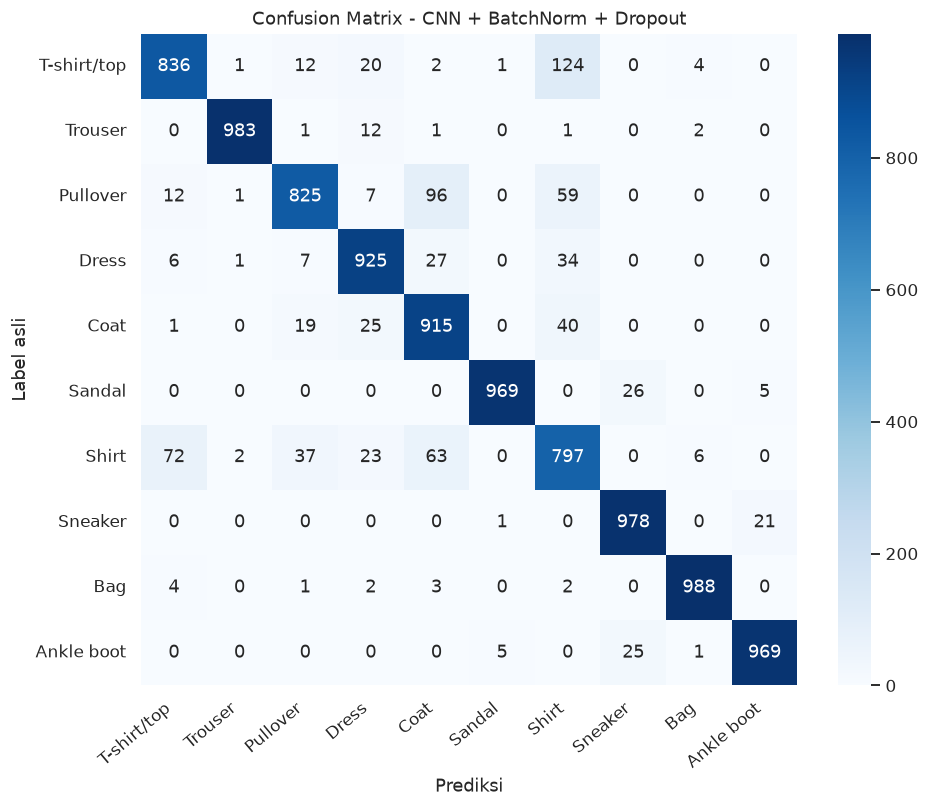

Pasangan kelas yang paling sering tertukar (asli -> prediksi):
  T-shirt/top  -> Shirt       :  124 gambar
  Pullover     -> Coat        :   96 gambar
  Shirt        -> T-shirt/top :   72 gambar
  Shirt        -> Coat        :   63 gambar
  Pullover     -> Shirt       :   59 gambar
  Coat         -> Shirt       :   40 gambar


In [26]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=[class_names[i] for i in range(10)],
            yticklabels=[class_names[i] for i in range(10)])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Prediksi"); plt.ylabel("Label asli")
plt.xticks(rotation=40, ha="right"); plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Pasangan kelas yang paling sering tertukar (di luar diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = [(cm_off[i, j], i, j) for i in range(10) for j in range(10) if i != j]
pairs.sort(reverse=True)
print("Pasangan kelas yang paling sering tertukar (asli -> prediksi):")
for count, i, j in pairs[:6]:
    print(f"  {class_names[i]:12s} -> {class_names[j]:12s}: {count:4d} gambar")

Jumlah gambar salah klasifikasi: 815 dari 10000 (8.15%)


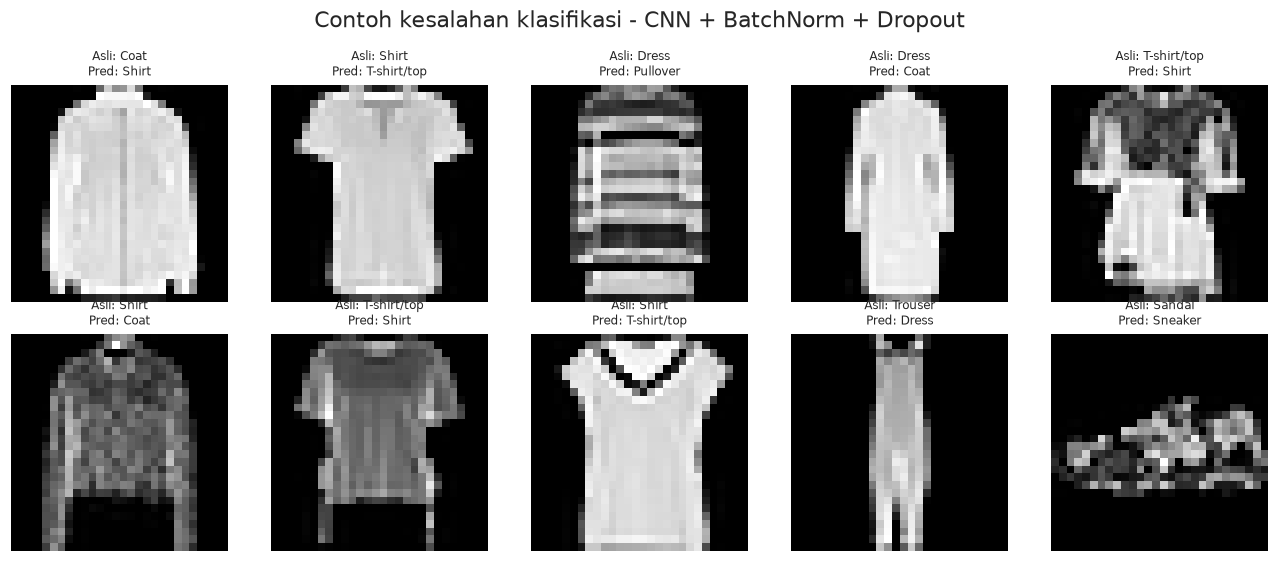

In [27]:
# Contoh gambar yang salah diklasifikasikan oleh model terbaik
wrong_idx = np.where(y_pred_best != y_test)[0]
print(f"Jumlah gambar salah klasifikasi: {len(wrong_idx)} dari {len(y_test)} "
      f"({len(wrong_idx) / len(y_test) * 100:.2f}%)")

rng = np.random.default_rng(SEED)
sample = rng.choice(wrong_idx, size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, idx in zip(axes.ravel(), sample):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[idx]]}\nPred: {class_names[y_pred_best[idx]]}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Contoh kesalahan klasifikasi - {best_name}")
plt.tight_layout()
plt.show()

Layer konvolusi pertama: Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


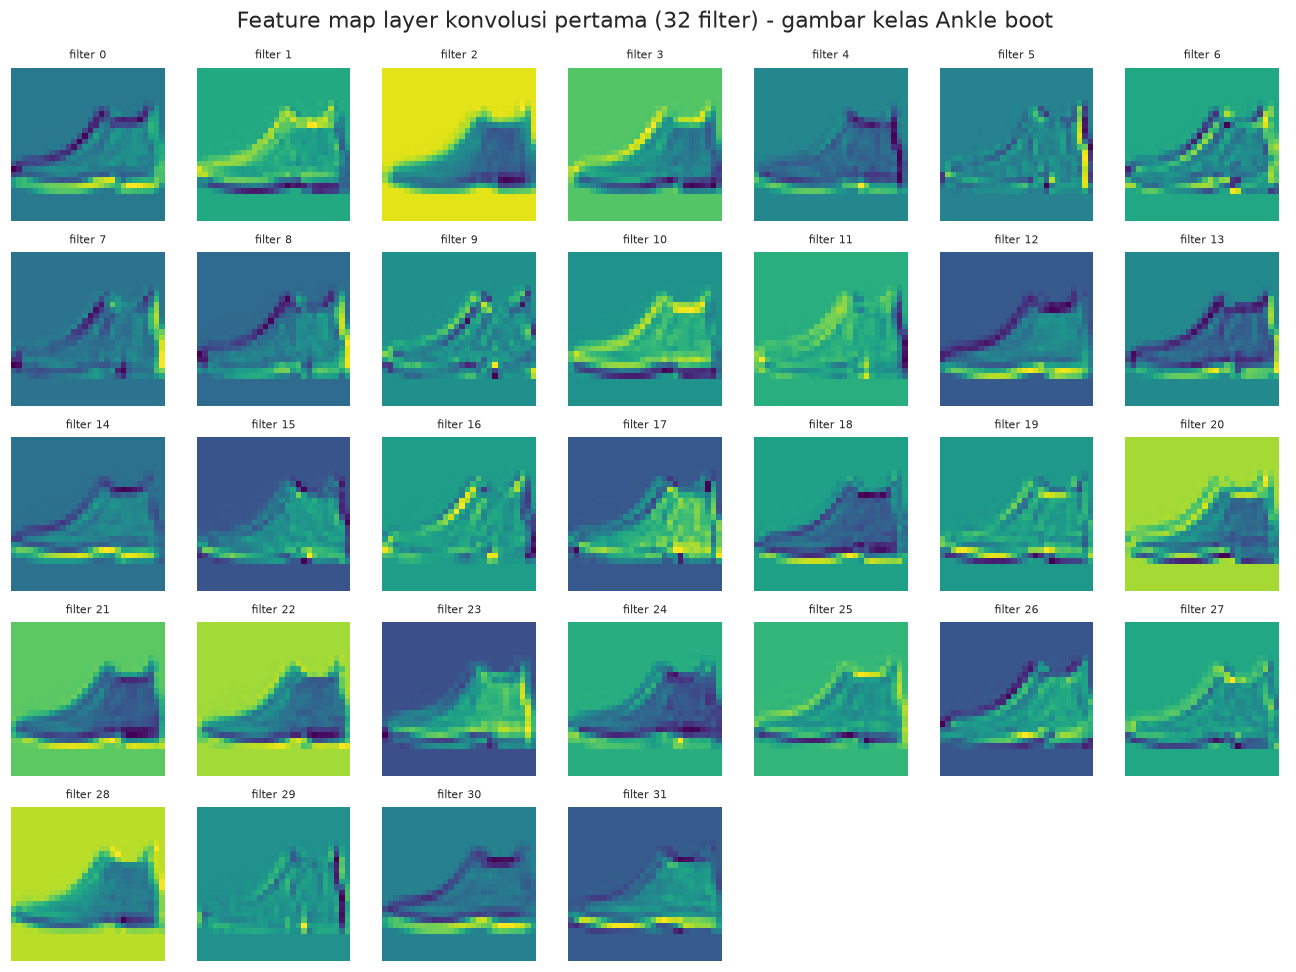

Bentuk feature map: (32, 28, 28)
Rentang aktivasi: -1.300 - 0.906
Jumlah filter yang hampir mati (aktivasi maksimum < 0.01): 2


In [28]:
# Visualisasi feature map layer konvolusi pertama model terbaik
first_conv = best_model.features[0]
print("Layer konvolusi pertama:", first_conv)

sample_idx = 0
img = X_test_t[sample_idx:sample_idx + 1].to(device)   # bentuk (1, 1, 28, 28)

with torch.no_grad():
    fmaps = first_conv(img).cpu().numpy()[0]            # (32, 28, 28)

fig, axes = plt.subplots(5, 7, figsize=(12, 9))
for ch, ax in enumerate(axes.ravel()):
    if ch < fmaps.shape[0]:
        ax.imshow(fmaps[ch], cmap="viridis")
        ax.set_title(f"filter {ch}", fontsize=7)
    ax.axis("off")
plt.suptitle(f"Feature map layer konvolusi pertama ({fmaps.shape[0]} filter) - "
             f"gambar kelas {class_names[y_test[sample_idx]]}")
plt.tight_layout()
plt.show()

print("Bentuk feature map:", fmaps.shape)
print(f"Rentang aktivasi: {fmaps.min():.3f} - {fmaps.max():.3f}")
print("Jumlah filter yang hampir mati (aktivasi maksimum < 0.01):",
      int((fmaps.max(axis=(1, 2)) < 0.01).sum()))

In [29]:
# Analisis kuantitatif pola yang ditangkap filter layer pertama.
# Setiap filter berukuran 3x3 (9 bobot), sehingga secara struktural hanya bisa merespons pola lokal:
# tepi/gradien dengan orientasi tertentu, atau bintik kontras (blob).
kernels = first_conv.weight.detach().cpu().numpy()[:, 0]          # (32, 3, 3)
coords = np.array([[-1, -1], [0, -1], [1, -1],
                   [-1, 0], [0, 0], [1, 0],
                   [-1, 1], [0, 1], [1, 1]], dtype=np.float32)

# Arah gradien dominan tiap kernel = jumlah bobot x koordinat pikselnya
gx = (kernels * coords[:, 0].reshape(1, 3, 3)).sum(axis=(1, 2))
gy = (kernels * coords[:, 1].reshape(1, 3, 3)).sum(axis=(1, 2))
magnitude = np.hypot(gx, gy)
angle = np.degrees(np.arctan2(gy, gx)) % 180


def kategori(mag, ang):
    if mag < 0.05:
        return "blob / low-pass"
    if ang < 22.5 or ang >= 157.5:
        return "tepi horizontal"
    if 67.5 <= ang < 112.5:
        return "tepi vertikal"
    return "tepi diagonal"


kategori_filter = [kategori(m, a) for m, a in zip(magnitude, angle)]
tabel = pd.DataFrame({
    "filter": range(len(kernels)),
    "|gradien|": magnitude.round(3),
    "sudut (deg)": angle.round(1),
    "pola": kategori_filter,
})
print(tabel.to_string(index=False))
print()
print("Rekap pola yang ditangkap 32 filter layer pertama:")
print(pd.Series(kategori_filter).value_counts().to_string())

 filter  |gradien|  sudut (deg)            pola
      0      0.890    52.900002   tepi diagonal
      1      0.741    55.900002   tepi diagonal
      2      0.513    16.000000 tepi horizontal
      3      1.098    36.400002   tepi diagonal
      4      0.807   131.300003   tepi diagonal
      5      0.072    34.200001   tepi diagonal
      6      0.330     8.600000 tepi horizontal
      7      0.959   175.100006 tepi horizontal
      8      1.100    21.100000 tepi horizontal
      9      0.079    46.599998   tepi diagonal
     10      0.762    63.200001   tepi diagonal
     11      0.945     5.100000 tepi horizontal
     12      1.013    78.699997   tepi vertikal
     13      0.775    45.599998   tepi diagonal
     14      0.670   108.300003   tepi vertikal
     15      0.267   136.600006   tepi diagonal
     16      0.568   178.500000 tepi horizontal
     17      0.134     3.000000 tepi horizontal
     18      0.281    80.000000   tepi vertikal
     19      0.190    79.400002   tepi v

In [30]:
CLASS_SOURCES = {
    "ANN": r"""
class ANN(nn.Module):
    # Baseline: flatten gambar 28x28 menjadi 784, lalu 2 hidden layer

    def __init__(self, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes),   # output logit, tanpa Softmax
        )

    def forward(self, x):
        return self.net(x)
""",
    "SimpleCNN": r"""
class SimpleCNN(nn.Module):
    # CNN sederhana: 2 blok Conv -> ReLU -> MaxPool, lalu classifier

    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes),   # output logit
        )

    def forward(self, x):
        return self.classifier(self.features(x))
""",
    "CNNBatchNorm": r"""
class CNNBatchNorm(nn.Module):
    # CNN 3.2 + BatchNorm2d setelah setiap Conv, BatchNorm1d + Dropout sebelum layer output

    def __init__(self, n_classes=10, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(128, n_classes),   # output logit
        )

    def forward(self, x):
        return self.classifier(self.features(x))
""",
}

import json

best_cls_name = type(best_model).__name__

# Semua artefak model disimpan di folder assets/ agar siap dipakai pada tugas Deployment
ASSETS_DIR = "assets"
os.makedirs(ASSETS_DIR, exist_ok=True)

torch.save(best_model.state_dict(), f"{ASSETS_DIR}/model.pth")
with open(f"{ASSETS_DIR}/model_architecture.py", "w") as f:
    f.write("# Arsitektur model terbaik hasil Tugas 2 Deep Learning (2_DL_5054251028.ipynb).\n")
    f.write("# Salinan definisi class pada section 3 notebook, agar bisa dipakai ulang pada tugas Deployment.\n\n")
    f.write("import torch.nn as nn\n\n\n")
    f.write(CLASS_SOURCES[best_cls_name])

with open(f"{ASSETS_DIR}/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2, ensure_ascii=False)

print("Model terbaik  :", best_name)
print("Folder artefak :", ASSETS_DIR)
for name in sorted(os.listdir(ASSETS_DIR)):
    print(f"  {name:24s} {os.path.getsize(f'{ASSETS_DIR}/{name}') / 1024:8.1f} KB")
print()
print(open(f"{ASSETS_DIR}/model_architecture.py").read())

Model terbaik  : CNN + BatchNorm + Dropout
Folder artefak : assets
  class_names.json              0.2 KB
  model.pth                  1657.3 KB
  model_architecture.py         1.1 KB

# Arsitektur model terbaik hasil Tugas 2 Deep Learning (2_DL_5054251028.ipynb).
# Salinan definisi class pada section 3 notebook, agar bisa dipakai ulang pada tugas Deployment.

import torch.nn as nn



class CNNBatchNorm(nn.Module):
    # CNN 3.2 + BatchNorm2d setelah setiap Conv, BatchNorm1d + Dropout sebelum layer output

    def __init__(self, n_classes=10, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
           

In [31]:
# Export ke ONNX agar model bisa dijalankan tanpa PyTorch dan tanpa GPU (onnxruntime CPU)
import onnx
import onnxruntime as ort

best_model.eval()
dummy_input = torch.zeros(1, 1, 28, 28, device=device)
onnx_path = f"{ASSETS_DIR}/model.onnx"

torch.onnx.export(
    best_model,
    dummy_input,
    onnx_path,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17,
    do_constant_folding=True,
    dynamo=False,
)

onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
print("Input    :", session.get_inputs()[0].name, session.get_inputs()[0].shape)
print("Output   :", session.get_outputs()[0].name, session.get_outputs()[0].shape)
print("Provider :", session.get_providers())

# Bandingkan output PyTorch dan ONNX pada seluruh test set (batch terakhir tidak penuh,
# sehingga sekaligus menguji sumbu batch yang dinamis)
with torch.no_grad():
    logits_torch = torch.cat([best_model(xb.to(device)).cpu() for xb, _ in test_loader]).numpy()
logits_onnx = np.concatenate([
    session.run(["logits"], {"input": xb.numpy()})[0] for xb, _ in test_loader
])

print(f"Selisih absolut maksimum PyTorch vs ONNX : {np.abs(logits_torch - logits_onnx).max():.2e}")
print("Prediksi kelas identik                   :",
      bool((logits_torch.argmax(1) == logits_onnx.argmax(1)).all()))
print(f"Akurasi model ONNX pada test set         : "
      f"{accuracy_score(y_test, logits_onnx.argmax(1)):.4f}")
print(f"Ukuran model.onnx                        : {os.path.getsize(onnx_path) / 1024:.1f} KB")

Input    : input ['batch', 1, 28, 28]
Output   : logits ['batch', 10]
Provider : ['CPUExecutionProvider']


Selisih absolut maksimum PyTorch vs ONNX : 5.20e-03
Prediksi kelas identik                   : True
Akurasi model ONNX pada test set         : 0.9185
Ukuran model.onnx                        : 1651.5 KB


In [32]:
# Verifikasi: muat ulang state_dict ke instance baru dari file arsitektur, pastikan prediksinya identik
with open(f"{ASSETS_DIR}/model_architecture.py") as f:
    src = f.read()

namespace = {"nn": nn}
exec(src, namespace)
reloaded = namespace[best_cls_name]().to(device)
reloaded.load_state_dict(torch.load(f"{ASSETS_DIR}/model.pth", map_location=device))
reloaded.eval()

y_pred_reload = predict_labels(reloaded, test_loader)
print("Prediksi identik setelah reload:", bool((y_pred_reload == y_pred_best).all()))
print(f"Akurasi model hasil reload: {accuracy_score(y_test, y_pred_reload):.4f}")

Prediksi identik setelah reload: True
Akurasi model hasil reload: 0.9185


# 5. Analisis

### 5.1 Ringkasan hasil eksperimen

| Model | Jumlah Parameter | Accuracy | Precision (macro) | Recall (macro) | F1-Score (macro) |
|---|---|---|---|---|---|
| ANN (baseline) | 235.146 | 0.8832 | 0.8847 | 0.8832 | 0.8819 |
| CNN Sederhana | 421.642 | 0.9174 | 0.9180 | 0.9174 | 0.9168 |
| CNN + BatchNorm + Dropout | 422.090 | **0.9185** | **0.9204** | **0.9185** | **0.9188** |

Semua metrik dihitung pada test set resmi Fashion-MNIST (10.000 gambar) yang tidak dipakai untuk training maupun validasi. Kelasnya seimbang, jadi accuracy dan F1 macro hampir sama. Dengan n = 10.000, galat baku accuracy di sekitar 0,92 adalah 0,27 poin persen, sehingga selisih di bawah 0,5 poin belum bisa dianggap beda nyata.

**1. ANN baseline cukup baik, tapi membuang struktur spasial.**

ANN mencapai accuracy 0,8832 dengan 235.146 parameter. Setelah `nn.Flatten()`, gambar 28×28 menjadi vektor 784 nilai, sehingga piksel bertetangga seperti (0,0) dan (0,1) diperlakukan sebagai fitur yang saling lepas. Tepi, sudut, dan bentuk lokal tidak pernah dipelajari secara eksplisit. Tidak ada weight sharing: setiap piksel punya bobot sendiri ke 256 neuron (200.704 bobot hanya di layer pertama), jadi pola yang sama harus dipelajari ulang di tiap posisi. Pakaian yang bergeser beberapa piksel juga menghasilkan aktivasi yang sangat berbeda.

Meski begitu ANN tetap dapat 88%, karena objek di Fashion-MNIST sudah terpusat dan berskala seragam. Untuk kelas bersiluet jelas (Trouser, Bag, Sandal, Sneaker, Ankle boot), bentuk global saja sudah cukup. Learning curve-nya menunjukkan overfitting yang baru mulai: loss validasi minimum 0,2779 di epoch 9 lalu naik ke 0,2889 di epoch 10, sementara loss training terus turun ke 0,2435. Akurasi validasi terbaik 0,9003 (epoch 9) juga lebih tinggi dari nilai akhirnya 0,8983. Gap train-validation akhir +1,14 poin.

**2. CNN sederhana naik 3,4 poin, padahal layer konvolusinya hanya 4,5% parameter.**

| Metrik | ANN | CNN Sederhana | Perubahan |
|---|---|---|---|
| Accuracy | 0.8832 | **0.9174** | +3,42 poin |
| F1-Score macro | 0.8819 | **0.9168** | +3,49 poin |
| Jumlah gambar salah (dari 10.000) | 1.168 | **826** | -29,3% |
| Jumlah parameter | 235.146 | 421.642 | +79% |

Dari 421.642 parameter CNN, hanya 18.816 (4,5%) yang ada di dua layer konvolusi (320 + 18.496). Sisanya, 402.826, ada di classifier fully-connected (3136×128). Jadi CNN menang bukan karena parameternya lebih banyak, tapi karena arsitekturnya cocok untuk gambar.

Filter 3×3 hanya melihat 9 piksel bertetangga, sehingga belajar pola lokal seperti tepi, sudut, dan tekstur kain. Filter yang sama digeser ke seluruh gambar, jadi cukup 288 bobot untuk memindai semua posisi, bukan 200.704, dan pola yang dipelajari di satu tempat langsung berlaku di tempat lain. Blok kedua menggabungkan tepi dari blok pertama menjadi bagian bentuk seperti kerah, lengan, atau sol sepatu, hal yang tidak bisa dilakukan ANN. MaxPooling meringkas area 2×2 dan memberi sedikit toleransi terhadap pergeseran objek.

CNN melewati akurasi validasi terbaik ANN (0,9003) sejak epoch 3 (0,9110). Di akhir training gap train-validation-nya +2,02 poin, dengan loss validasi minimum 0,1946 di epoch 9 yang naik lagi ke 0,2076 di epoch 10. Pola overfitting ringan ini sama seperti ANN, hanya di level akurasi yang lebih tinggi.

**3. BatchNorm mempercepat konvergensi, tapi akurasi akhirnya setara.**

| Metrik | CNN Sederhana | CNN + BN + Dropout |
|---|---|---|
| Epoch 1, val accuracy | 0.8273 | **0.9080** |
| Epoch 1, val loss | 0.4461 | **0.2508** |
| Epoch 3, val accuracy | 0.9110 | **0.9227** |
| Val accuracy terbaik | 0.9300 (epoch 9) | **0.9332** (epoch 9) |
| Accuracy test | 0.9174 | **0.9185** |
| F1 macro test | 0.9168 | **0.9188** |
| Gap train-val akhir | +2,02 poin | +2,41 poin |
| Val loss akhir (epoch 10) | 0.2076 | **0.1967** |
| Waktu per epoch | 0,71 s | 0,89 s |

BatchNorm paling terasa pada kecepatan konvergensi. Di epoch pertama akurasi validasi sudah 0,9080 vs 0,8273, selisih 8,1 poin. BatchNorm menormalkan aktivasi tiap layer sehingga skalanya stabil, dan learning rate 1e-3 bisa dipakai tanpa warm-up. Loss validasi model BN juga turun hampir monoton sampai epoch 9.

Dropout 0,5 bekerja, tapi belum cukup. Gap train-validation justru lebih besar (+2,41 vs +2,02 poin) karena akurasi training naik lebih tinggi (0,9531 vs 0,9463), dan loss validasi naik dari 0,1812 di epoch 9 ke 0,1967 di epoch 10. Dengan 10 epoch dan 54.000 gambar, manfaat Dropout kemungkinan baru terlihat kalau training lebih panjang atau data lebih sedikit.

Selisih test set antara CNN dan CNN + BN + Dropout hanya 0,11 poin (11 dari 10.000 gambar), jauh di bawah galat baku 0,27 poin, jadi keduanya bisa dianggap setara. Keuntungan BN yang nyata ada di efisiensi training: model mencapai akurasi tinggi sekitar 3 kali lebih cepat. Dua kali eksekusi menghasilkan angka identik, jadi selisih ini bukan noise antar-run, tapi dengan satu seed tetap belum bisa disebut bermakna.

**4. Kesalahan terkonsentrasi di pakaian atas.**

| Kelas | Precision | Recall | F1-Score |
|---|---|---|---|
| Shirt | 0.7540 | 0.7970 | **0.7749** |
| T-shirt/top | 0.8980 | 0.8360 | 0.8659 |
| Pullover | 0.9146 | 0.8250 | 0.8675 |
| Coat | 0.8266 | 0.9150 | 0.8685 |
| Dress | 0.9122 | 0.9250 | 0.9186 |
| Sneaker | 0.9504 | 0.9780 | 0.9640 |
| Ankle boot | 0.9739 | 0.9690 | 0.9714 |
| Sandal | 0.9928 | 0.9690 | 0.9808 |
| Bag | 0.9870 | 0.9880 | 0.9875 |
| Trouser | 0.9949 | 0.9830 | **0.9889** |

Pasangan yang paling sering tertukar: T-shirt/top ke Shirt (124), Pullover ke Coat (96), Shirt ke T-shirt/top (72), Shirt ke Coat (63), Pullover ke Shirt (59), dan Coat ke Shirt (40). Keenamnya ada di dalam kelompok pakaian atas, sesuai dugaan dari EDA bahwa prototipe kelas-kelas ini hampir identik.

Dari 815 gambar yang salah (8,15%), 702 (86%) berasal dari lima kelas pakaian atas: T-shirt/top (164), Shirt (203), Pullover (175), Coat (85), dan Dress (75). Padahal kelima kelas itu hanya 50% dari data. Lima kelas bersiluet jelas (Trouser, Sandal, Sneaker, Bag, Ankle boot) hanya menyumbang 113 kesalahan (14%).

Penyebabnya, beda antara T-shirt, Shirt, Pullover, dan Coat ada di detail kecil seperti kerah, bentuk lengan, kancing, dan panjang badan. Setelah dua kali MaxPooling resolusi turun dari 28×28 ke 7×7, dan detail itu sebagian hilang. `Shirt` paling terdampak karena paling generik: ia sering tertukar dengan T-shirt/top (72) dan Coat (63), dan juga menerima kesalahan dari T-shirt/top (124) dan Pullover (59), sehingga precision-nya turun ke 0,7540.

**5. Layer konvolusi pertama bekerja sebagai detektor tepi.**

Layer pertama punya 32 filter 3×3, hanya 9 bobot per filter, sehingga secara struktur hanya bisa menangkap tepi atau gradien dengan orientasi tertentu. Dari arah gradien dominan tiap kernel (jumlah bobot dikali koordinat piksel), diperoleh 15 filter untuk tepi diagonal, 9 untuk horizontal, dan 8 untuk vertikal. Hasilnya mirip bank filter Sobel atau Gabor. Filter dengan |gradien| terbesar (1,386 dan 1,098) adalah detektor tepi vertikal dan diagonal yang tegas, sedangkan yang terkecil (0,072 dan 0,079) hampir datar dan nyaris tidak merespons apa pun.

Feature map mengonfirmasi hal ini: 2 dari 32 filter hampir mati, dengan aktivasi maksimum di bawah 0,01. Filter ini dimatikan oleh ReLU dan tidak pernah berguna sejak inisialisasi acak. Rentang aktivasi feature map adalah -1,300 sampai 0,906. Setelah ReLU, nilai negatif jadi 0, sehingga pada satu gambar contoh hanya sekitar separuh filter yang aktif, menandai batas siluet dan lekukan kain.

Setelah satu layer konvolusi, informasi yang ada masih berupa tepi. Konsep jenis pakaian baru terbentuk dari kombinasi tepi di layer kedua dan classifier. Filter 3×3 juga tidak bisa menangkap ciri global seperti rasio panjang lengan terhadap badan, karena receptive field-nya kecil dan baru diperluas sedikit oleh dua kali pooling.

**6. Keterbatasan eksperimen.**

Eksperimen memakai satu seed, 10 epoch, dan tanpa early stopping, padahal loss validasi sudah naik di epoch terakhir pada ketiga model. Early stopping di epoch 8-9 akan memberi hasil sedikit lebih baik dan lebih hemat waktu. Tidak ada augmentasi data, padahal horizontal flip dan random crop kecil biasanya menambah 0,5 sampai 1,5 poin pada Fashion-MNIST dan akan membantu kelas pakaian atas.

Test set juga dipakai untuk memilih model terbaik. Ini sedikit menyimpang dari prosedur yang benar, karena pemilihan model seharusnya memakai validation set dan test set hanya disentuh sekali. Hyperparameter (learning rate, dropout rate, jumlah filter, batch size, jumlah epoch) tidak di-tuning dan tidak ada validasi silang. Hasil identik hanya terjamin di mesin ini, karena `torch.use_deterministic_algorithms(True)` dan `CUBLAS_WORKSPACE_CONFIG` tidak menjamin hal yang sama di GPU atau versi PyTorch lain. Perbandingan ANN vs CNN juga belum menyamakan jumlah parameter (235.146 vs 421.642), jadi pembanding yang lebih adil adalah ANN dengan jumlah parameter yang sama.

# 6. Kesimpulan dan Saran

**Kesimpulan:**

1. CNN jelas mengungguli ANN: accuracy 0,9174 vs 0,8832 (+3,4 poin), F1 macro 0,9168 vs 0,8819, dan jumlah kesalahan turun 29% (1.168 menjadi 826 gambar). Dua layer konvolusinya hanya berisi 18.816 parameter (4,5% dari 421.642), jadi keunggulannya datang dari cara arsitektur memproses gambar, bukan dari kapasitas. Filter 3×3 menangkap pola lokal, weight sharing memakai filter yang sama di seluruh gambar, layer bertingkat membangun bentuk dari tepi, dan MaxPooling memberi toleransi pergeseran. ANN yang meratakan gambar kehilangan semua struktur itu.
2. CNN + BatchNorm + Dropout adalah model terbaik dengan accuracy 0,9185 dan F1 macro 0,9188. Artefaknya disimpan di `assets/` sebagai `model.pth`, `model_architecture.py`, `class_names.json`, dan `model.onnx`. Model hasil reload memberi prediksi identik, dan model ONNX memberi akurasi yang sama (0,9185) dengan selisih logit maksimum 5,2e-03. Selisihnya dengan CNN sederhana hanya 0,11 poin, di bawah galat baku 0,27 poin, jadi keduanya setara.
3. Manfaat terbesar BatchNorm ada di efisiensi training, bukan akurasi akhir. Di epoch pertama akurasi validasi sudah 0,9080 vs 0,8273 (+8,1 poin), loss validasi 0,2508 vs 0,4461, dan akurasi validasi terbaiknya 0,9332. Dropout 0,5 menahan overfitting tapi belum cukup pada 10 epoch: gap train-validation justru sedikit lebih besar (+2,41 vs +2,02 poin) dan loss validasi naik lagi di epoch 10.
4. Kesalahan terkonsentrasi di pakaian atas. 86% dari 815 kesalahan berasal dari T-shirt/top, Shirt, Pullover, Coat, dan Dress, dengan `Shirt` paling sulit (F1 0,7749, precision 0,7540). Detail pembeda seperti kerah, lengan, dan kancing hilang setelah dua kali pooling menurunkan resolusi 28×28 ke 7×7. Kelas bersiluet jelas (Trouser, Bag, Sandal, Ankle boot, Sneaker) semuanya di atas F1 0,96.
5. Layer konvolusi pertama bekerja sebagai detektor tepi: dari 32 filter 3×3, 15 merespons tepi diagonal, 9 horizontal, dan 8 vertikal, sementara 2 filter hampir mati karena ReLU. Fitur yang lebih bermakna baru terbentuk di layer berikutnya, jadi satu blok konvolusi belum cukup untuk membedakan kelas yang mirip.
6. Hasil bisa direproduksi: dengan seed 42, `torch.use_deterministic_algorithms(True)`, dan `CUBLAS_WORKSPACE_CONFIG`, dua eksekusi penuh menghasilkan angka identik.

**Saran untuk eksperimen selanjutnya:**

1. **Early stopping dan learning-rate scheduler**, misalnya `ReduceLROnPlateau` atau cosine annealing. Loss validasi minimum ketiga model ada di epoch 8-9, jadi 10 epoch tanpa early stopping sudah mulai overfitting.
2. **Augmentasi data:** `RandomHorizontalFlip`, `RandomAffine` kecil (rotasi ±10° dan translasi 10%), dan `RandomCrop(28, padding=4)`. Ini yang paling menjanjikan untuk kelas pakaian atas karena menambah variasi bentuk tanpa mengubah label.
3. **Receptive field dan kedalaman:** tambah blok konvolusi ketiga (32, 64, lalu 128 filter) dengan pooling, atau pakai `GlobalAveragePooling` untuk mengurangi 402.826 parameter di classifier. ResNet-18 yang diadaptasi ke 1 channel bisa jadi pembanding atas.
4. **Klasifikasi bertingkat:** tentukan dulu kelompok besar (pakaian atas, bawah, alas kaki, aksesori), baru kelas di dalamnya. Ini langsung menyasar sumber 86% kesalahan dan bisa digabung dengan loss berbobot untuk `Shirt`.
5. **Pemilihan model yang benar:** pakai validation set, bukan test set, untuk memilih model. Lakukan grid atau random search untuk learning rate, dropout rate, jumlah filter, dan batch size, lalu validasi dengan stratified k-fold dan beberapa seed supaya bisa melaporkan rata-rata dan standar deviasi.

**Deployment:** model ONNX dilayani lewat FastAPI (kode di folder `src/`) dan bisa dicoba langsung di https://fashion.alfiwillianz.my.id. Alur inference-nya: gambar diubah ke grayscale 28×28 (latar terang otomatis di-invert karena Fashion-MNIST berlatar hitam), nilai piksel `float32` dibagi 255, bentuk input `(1, 1, 28, 28)`, output 10 logit, `softmax` untuk probabilitas, dan `argmax` untuk label. Dokumentasi API ada di https://fashion.alfiwillianz.my.id/docs.